# Modeling and evaluation: core models
**Pablo · CAP 3764 · Fall 2026**

**Goal:** predict `Financial_Risk_Label` (1 = at risk, ~16% of companies) from company financials,
macro indicators and sector.

**Approach**
1. Stratified 80/20 train/test split, so both parts keep the ~16% at-risk rate. The test set is scored once, at the end.
2. Four models in sklearn Pipelines (scaling and encoding are fit on training data only, so there is no leakage):
   a do-nothing baseline, logistic regression, random forest and gradient boosting.
3. Class imbalance is handled with class weights. Accuracy is not reported: always predicting
   "not at risk" already scores about 84%.
4. 5-fold stratified cross-validation on the training set, then one test-set evaluation.

The reusable code lives in `src/risk_data/modeling.py` (tested in `tests/test_modeling.py`).
Follow-up notebooks: `05_feature_importance`, `06_leakage_and_sensitivity`, `07_tuning`.

Run **Kernel → Restart Kernel and Run All Cells** with the `Python (cap3764-risk)` kernel.
Requires `data/processed/cleaned_data.csv` (run `collect.py` then `clean.py`).

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

from risk_data import modeling as m

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = root / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load data and split
Identifiers (`Company_ID`, `Date`) are dropped: after cleaning each company appears once, so they carry no signal.

In [2]:
df = m.load_model_data(root / "data" / "processed" / "cleaned_data.csv")
X, y = m.split_features(df)
X_train, X_test, y_train, y_test = m.make_train_test_split(X, y)

pd.DataFrame({
    "rows": [len(y_train), len(y_test)],
    "at_risk_rate": [y_train.mean(), y_test.mean()],
}, index=["train", "test"]).round(3)

,rows,at_risk_rate
train,2860,0.161
test,715,0.161


## 2. Cross-validation on the training set
All models see the same stratified folds. PR-AUC and recall matter most: the at-risk class is the rare one we care about.

In [3]:
models = m.build_models(X)
cv_table = m.cross_validate_models(models, X_train, y_train)
cv_table[["roc_auc_mean", "pr_auc_mean", "f1_mean", "precision_mean", "recall_mean", "pr_auc_std"]].round(3)

,roc_auc_mean,pr_auc_mean,f1_mean,precision_mean,recall_mean,pr_auc_std
dummy,0.500,0.161,0.000,0.000,0.000,0.000
logistic_regression,0.969,0.886,0.769,0.669,0.907,0.013
random_forest,1.000,1.000,0.996,0.991,1.000,0.000
gradient_boosting,1.000,0.997,0.996,0.996,0.996,0.005


## 3. Test-set evaluation
Each model is refit on the full training set and scored once on the held-out test set.

In [4]:
fitted = {name: model.fit(X_train, y_train) for name, model in models.items()}
test_table = pd.DataFrame({name: m.evaluate(model, X_test, y_test) for name, model in fitted.items()}).T
test_table.round(3)

,precision,recall,f1,roc_auc,pr_auc
dummy,0.000,0.000,0.000,0.500,0.161
logistic_regression,0.671,0.922,0.777,0.968,0.890
random_forest,1.000,1.000,1.000,1.000,1.000
gradient_boosting,1.000,0.991,0.996,1.000,1.000


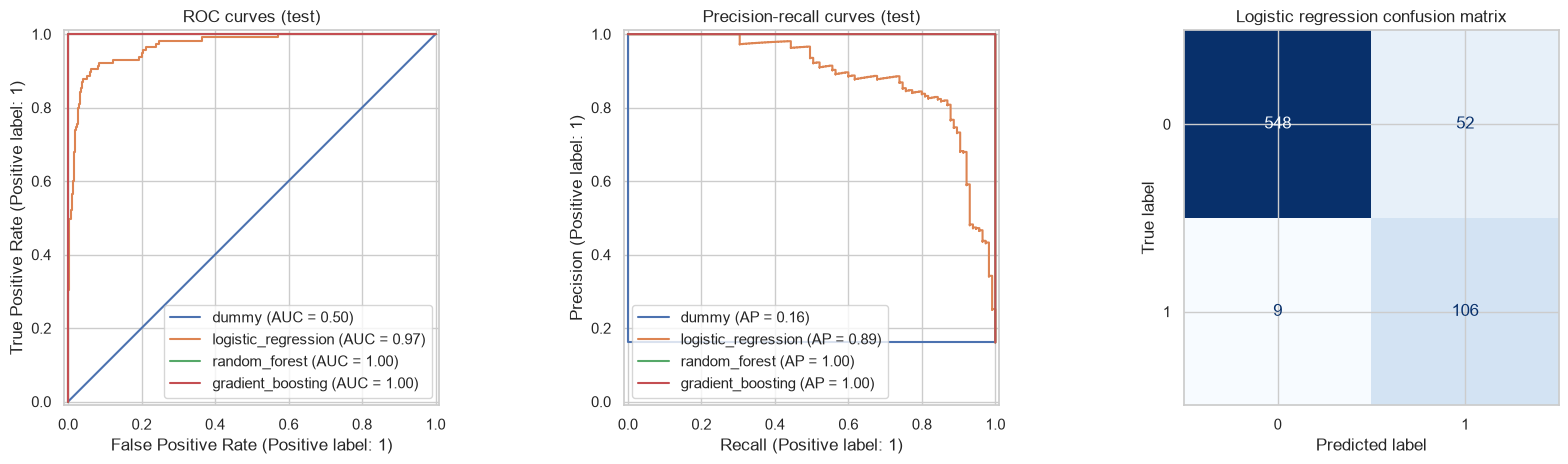

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for name, model in fitted.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[0], name=name)
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, ax=axes[1], name=name)
axes[0].set_title("ROC curves (test)")
axes[1].set_title("Precision-recall curves (test)")
ConfusionMatrixDisplay.from_estimator(fitted["logistic_regression"], X_test, y_test, ax=axes[2], cmap="Blues", colorbar=False)
axes[2].set_title("Logistic regression confusion matrix")
fig.tight_layout()
fig.savefig(FIG_DIR / "modeling_test_curves.png", dpi=150)
plt.show()

## 4. Interpretation and caveat

- **Every model beats the baseline.** The dummy model has ROC-AUC 0.50 and PR-AUC equal to the at-risk rate (~0.16), which is the no-skill level.
- **Logistic regression** is a solid linear baseline (test ROC-AUC about 0.97, recall about 0.92) but its precision is low (about 0.67), because class weighting makes it flag many safe companies.
- **Random forest and gradient boosting score close to 1.0** on every metric, in cross-validation and on the test set.
- **That is too good to trust.** Scores this high on real-world credit risk usually mean the label can be reconstructed from the features. `06_leakage_and_sensitivity.ipynb` tests this and re-evaluates without the offending features.
- Consequently, **do not report the all-features tree-model numbers as predictive performance** without the caveat from notebook 06.